# 01 · Définir le problème et explorer les données

**Étapes 1–2** du cas pratique · Slides 5, 10, 17–21, 23, 40, 44.

Ce notebook cadre le problème (étape 1) puis explore les données (étape 2). Chaque question numérotée est suivie, juste après le code qui permet d'y répondre, d'une cellule de réponse.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score

from financial_inclusion_africa import config
from financial_inclusion_africa.data import load_raw
from financial_inclusion_africa.evaluate import (
    classification_metrics,
    full_classification_report,
    theoretical_threshold,
)

config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 4)

## Étape 1 · Définir le problème

### 1.1 Le contexte

Jeu de données **Financial Inclusion in Africa** (Zindi), issu des enquêtes ménages FinScope 2016–2018 au Kenya, au Rwanda, en Tanzanie et en Ouganda. Chaque ligne est une personne interrogée ; la cible `bank_account` indique si elle possède un compte bancaire.

### 1.2 Le scénario métier

- **KaziPay** contacte (SMS puis agent) les personnes dont elle pense qu'elles ont un compte bancaire.
  - Contacter une personne **sans compte** coûte $C_{FP} = 0{,}5$ USD (faux positif).
  - **Ne pas** contacter une personne qui a un compte bancaire fait perdre $C_{FN} = 5$ USD (faux négatif).
- La **banque centrale** estime le nombre de personnes qui ont un compte bancaire par pays en additionnant les probabilités prédites.

$$\text{Coût} = C_{FP}\cdot FP + C_{FN}\cdot FN \qquad\qquad t^* = \frac{C_{FP}}{C_{FP} + C_{FN}}$$

Les coûts sont fixés une fois pour toutes dans `config.py`.

In [2]:
df = load_raw()
print(f"{df.shape[0]:,} lignes × {df.shape[1]} colonnes")
df.head()

23,524 lignes × 13 colonnes


,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,1,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,0,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,1,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,0,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,0,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed


### Q1.1 · Unité statistique, cible, classe positive, type de problème

In [3]:
counts = df[config.TARGET].value_counts().rename({0: "No (0)", 1: "Yes (1)"})
prevalence = df[config.TARGET].mean()
display(counts.to_frame("effectif").assign(part=lambda t: t["effectif"] / len(df)))
print(f"Prévalence de la classe positive : {prevalence:.2%}")

,effectif,part
bank_account,,
No (0),20212,0.8592
Yes (1),3312,0.1408


Prévalence de la classe positive : 14.08%


**Réponse Q1.1.**

- **Unité statistique** : une **personne interrogée** (un adulte d'un ménage enquêté par FinScope), dans un pays et une année donnés. Ce n'est ni le ménage ni le pays.
- **Variable cible** : `bank_account`, encodée 1 = *Yes*, 0 = *No* par `load_raw()`.
- **Classe positive** : **1 = la personne possède un compte bancaire**. C'est la classe que KaziPay veut trouver ; elle est **minoritaire** (14,08 %, soit 3 312 personnes sur 23 524).
- **Type de problème** : **classification binaire supervisée, déséquilibrée** (environ 1 positif pour 6 négatifs). On attend du modèle des **probabilités** et pas seulement une étiquette, parce que les deux usages métier en ont besoin : un seuil fondé sur les coûts pour KaziPay et une somme de probabilités pour la banque centrale.

### Q1.2 · Le modèle qui répond « Non » pour tout le monde

In [4]:
X, y = df.drop(columns=config.TARGET), df[config.TARGET]
t_star = theoretical_threshold(config.COST_FP, config.COST_FN)

# Deux planchers : « toujours Non » (proba 0 pour tous) et « prior » (proba = prévalence pour tous)
planchers = {
    "« toujours Non »": DummyClassifier(strategy="most_frequent"),
    "« prior » (p = 14 %)": DummyClassifier(strategy="prior"),
}
proba = {name: m.fit(X, y).predict_proba(X)[:, 1] for name, m in planchers.items()}
pd.DataFrame({name: classification_metrics(y, p, t_star) for name, p in proba.items()})

,« toujours Non »,« prior » (p = 14 %)
pr_auc,0.1408,0.1408
roc_auc,0.5000,0.5000
brier,0.1408,0.1210
log_loss,5.0747,0.4064
accuracy,0.8592,0.1408
precision,0.0000,0.1408
recall,0.0000,1.0000
f1,0.0000,0.2468
cost,16560.0000,10106.0000


In [5]:
print("Rapport de classification · « toujours Non »\n")
print(full_classification_report(y, proba["« toujours Non »"], t_star))

Rapport de classification · « toujours Non »

              precision    recall  f1-score   support

      No (0)     0.8592    1.0000    0.9243     20212
     Yes (1)     0.0000    0.0000    0.0000      3312

    accuracy                         0.8592     23524
   macro avg     0.4296    0.5000    0.4621     23524
weighted avg     0.7382    0.8592    0.7941     23524



**Réponse Q1.2.** Le modèle « toujours Non » obtient une **accuracy de 85,92 %** ($= 1 - 14{,}08\,\%$, exactement la part de la classe majoritaire) et un **recall de 0** : il ne trouve **aucune** personne qui a un compte bancaire, KaziPay ne contacte personne et perd $3\,312 \times 5 = 16\,560$ USD de marge.

Le **rapport de classification** le montre classe par classe : tout semble excellent pour *No* (recall 1, F1 0,92) et tout vaut **0 pour *Yes***, la seule classe qui intéresse KaziPay. La moyenne pondérée (F1 0,79) est dominée par la classe majoritaire et masque cet échec ; la moyenne macro (recall 0,50) le révèle.

Les métriques de **probabilités** le sanctionnent aussi : en donnant une probabilité **0** à 3 312 personnes qui ont un compte, il obtient une **log-loss de 5,07**, contre **0,41** pour le plancher « prior », qui donne 14 % à tout le monde. La log-loss punit très fort les erreurs commises avec certitude. Le plancher « prior » est la référence à battre pour la log-loss (0,406) et le Brier (0,121) ; au seuil $t^*$ elle contacte tout le monde (recall 1, précision 0,14).

**Conclusion (slide 21)** : avec des classes déséquilibrées, l'accuracy est trompeuse. Un score de 86 % semble bon alors que le modèle est inutile. L'accuracy ne dit rien de la classe qui nous intéresse ; elle reste au mieux une métrique de contrôle, toujours comparée à ces **planchers** (`DummyClassifier`). Le vrai modèle de base, à battre par tous les modèles plus complexes, est la **régression logistique** (voir « Choix du modèle de base » ci-dessous).

### Q1.3 · Métrique principale et métriques secondaires

**Réponse Q1.3.**

| Rôle | Métrique | Pourquoi |
|---|---|---|
| **Principale** | **PR-AUC** (*average precision*) | Classe positive rare (14 %) : elle ne regarde que la qualité du classement **parmi les positifs**, sans être gonflée par les 86 % de vrais négatifs faciles (slides 18–19). Indépendante du seuil, donc utile pour comparer et régler les modèles avant de choisir $t^*$. Référence du hasard = prévalence ≈ 0,14. |
| Secondaire 1 | **Score de Brier** (+ ECE, diagramme de fiabilité) | Usage **banque centrale** : on additionne des probabilités, elles doivent être **calibrées** (slide 40). Le Brier mesure l'exactitude des probabilités elles-mêmes. |
| Secondaire 2 | **Coût total** $C_{FP}\cdot FP + C_{FN}\cdot FN$ au seuil retenu | Usage **KaziPay** : c'est la grandeur que l'entreprise veut minimiser, en dollars, lisible par le métier (slide 17). |

**Métriques rapportées en complément**, toujours en **moyenne ± écart-type** sur les plis de validation croisée :

- **ROC-AUC** : qualité du classement, à comparer avec la littérature ;
- **log-loss** : avec le Brier, juge les probabilités ; elle punit fortement les erreurs commises avec certitude ;
- au seuil retenu : **précision** (part des personnes contactées qui ont un compte), **recall** (part des personnes qui ont un compte que l'on contacte), **accuracy** ;
- le **rapport de classification complet** (`classification_report` : précision, recall, F1 et support par classe, moyennes macro et pondérée).

Ces métriques sont calculées par `classification_metrics()` et `full_classification_report()` dans `evaluate.py`, pour être identiques dans tous les notebooks.

### Choix du modèle de base (baseline)

**Décision : la régression logistique est notre modèle de base.** Tout modèle plus complexe (forêt aléatoire, boosting) devra la battre pour justifier sa complexité.

| Rôle | Modèle | Ce qu'il nous apprend |
|---|---|---|
| Plancher | `DummyClassifier` (« toujours Non », « prior ») | Le score obtenu **sans rien apprendre**. Un modèle qui ne le bat pas largement est cassé (Q1.2). |
| **Modèle de base** | **`LogisticRegression`** | Le score d'un modèle **simple, rapide et interprétable**. C'est la référence pour toutes les comparaisons suivantes. |

**Pourquoi la régression logistique ?** (slide 21 : *« modèle linéaire régularisé, simple et rapide »*)
- **Simple et rapide** : quelques secondes en validation croisée, peu d'hyperparamètres (la régularisation `C`).
- **Interprétable** : chaque coefficient se lit comme un *odds ratio* ; on peut l'expliquer à KaziPay et à la banque centrale.
- **Probabilités souvent bien calibrées** : elle est entraînée en minimisant la log-loss, ce qui sert directement la banque centrale (Q1.5) et le seuil $t^*$ (Q1.4).
- **Peu de variance** : elle surapprend peu, ce qui donne un point de comparaison stable pour le diagnostic biais–variance (étape 5).

**Règle de comparaison** : un modèle plus complexe ne « bat » la régression logistique que si son gain de PR-AUC dépasse l'**écart-type** entre les plis de validation croisée. Sinon, on garde le modèle le plus simple.

*Mise en œuvre à l'étape 5* (`LogisticRegression(max_iter=2000)` dans le pipeline de l'étape 3, évaluée avec le même objet `cv` que l'étape 4). On ne l'entraîne pas ici : le découpage train/test et le protocole d'évaluation ne sont pas encore en place.

### Q1.4 · Seuil théorique $t^*$

In [6]:
t_star_fn2 = theoretical_threshold(config.COST_FP, 2.0)
print(f"t* (C_FP = {config.COST_FP}, C_FN = {config.COST_FN}) = {t_star:.4f}")
print(f"t* (C_FP = {config.COST_FP}, C_FN = 2.0) = {t_star_fn2:.4f}")

t* (C_FP = 0.5, C_FN = 5.0) = 0.0909
t* (C_FP = 0.5, C_FN = 2.0) = 0.2000


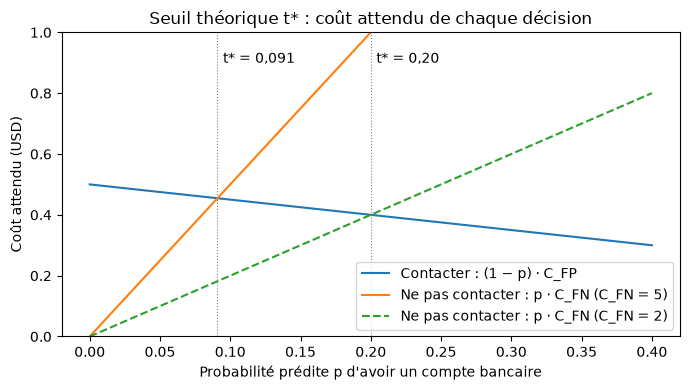

In [7]:
# Coût attendu d'une décision, pour une personne de probabilité p (probabilités calibrées)
p = np.linspace(0, 0.4, 401)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(p, (1 - p) * config.COST_FP, label="Contacter : (1 − p) · C_FP")
ax.plot(p, p * config.COST_FN, label="Ne pas contacter : p · C_FN (C_FN = 5)")
ax.plot(p, p * 2.0, ls="--", label="Ne pas contacter : p · C_FN (C_FN = 2)")
for t, lab in [(t_star, "t* = 0,091"), (t_star_fn2, "t* = 0,20")]:
    ax.axvline(t, color="grey", lw=0.8, ls=":")
    ax.annotate(lab, (t, 0.9), xytext=(4, 0), textcoords="offset points")
ax.set(xlabel="Probabilité prédite p d'avoir un compte bancaire", ylabel="Coût attendu (USD)",
       title="Seuil théorique t* : coût attendu de chaque décision", ylim=(0, 1))
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "01_seuil_theorique.png", dpi=150)
plt.show()

**Réponse Q1.4.** On contacte une personne de probabilité $p$ dès que le coût attendu de l'oubli dépasse celui du contact inutile (slide 44) :

$$p\,C_{FN} > (1-p)\,C_{FP} \iff p > t^* = \frac{C_{FP}}{C_{FP}+C_{FN}} = \frac{0{,}5}{0{,}5+5} = \frac{1}{11} \approx 0{,}091.$$

- **Pourquoi bien en dessous de 0,5 ?** Le seuil 0,5 n'est optimal que si les deux erreurs coûtent pareil. Ici rater un client coûte **10 fois** plus cher qu'un SMS inutile : on accepte jusqu'à 10 contacts inutiles pour gagner un client. Il suffit donc d'une chance sur 11 d'avoir un compte bancaire pour que le contact soit rentable.
- **Si $C_{FN}$ descend à 2 USD** : $t^* = 0{,}5/2{,}5 = 0{,}20$. Rater un client coûte moins cher, le seuil **monte**, KaziPay contacte **moins** de personnes (moins de faux positifs, plus de faux négatifs). Le seuil est une décision métier, pas une propriété du modèle.
- **Attention** : cette formule suppose des probabilités **calibrées**. Sinon le seuil empirique qui minimise le coût s'en écartera (étapes 8–9).

### Q1.5 · Ce que la banque centrale exige des probabilités

In [8]:
# Illustration sur des données simulées : deux jeux de scores de même ordre
rng = np.random.default_rng(config.RANDOM_STATE)
p_true = rng.beta(1, 6, size=10_000)       # vraies probabilités (prévalence ≈ 14 %)
y_sim = rng.binomial(1, p_true)
p_biased = p_true / 2                       # même classement, valeurs divisées par 2

pd.DataFrame(
    {
        "ROC-AUC": [roc_auc_score(y_sim, p_true), roc_auc_score(y_sim, p_biased)],
        "Σ p̂ (estimation)": [p_true.sum(), p_biased.sum()],
        "nombre réel de positifs": [y_sim.sum()] * 2,
    },
    index=["p̂ calibrée", "p̂ / 2 (mal calibrée)"],
).round(3)

,ROC-AUC,Σ p̂ (estimation),nombre réel de positifs
p̂ calibrée,0.779,1401.488,1412
p̂ / 2 (mal calibrée),0.779,700.744,1412


**Réponse Q1.5.** La banque centrale estime le nombre de personnes qui ont un compte bancaire par $\sum_i \hat p_i$. Cette somme n'est juste que si les probabilités sont **calibrées** : $P(Y=1 \mid \hat p = p) = p$ (slide 40). Parmi les personnes à qui le modèle donne 20 %, environ 20 % doivent effectivement avoir un compte bancaire, **dans chaque pays**.

**Pourquoi la ROC-AUC ne suffit pas** : elle ne juge que **l'ordre** des scores. Toute transformation croissante des probabilités la laisse inchangée. Dans la simulation ci-dessus, diviser toutes les probabilités par 2 donne **exactement la même ROC-AUC (0,779)**, mais l'estimation tombe de ≈ 1 400 à ≈ 700 personnes : une erreur de 50 %. *Discrimination ≠ calibration* : on mesurera la calibration à part (Brier, ECE, diagramme de fiabilité) et on la corrigera si nécessaire (étape 8).

### Q1.6 · Utiliser le genre pour décider qui contacter ?

In [9]:
pd.crosstab(
    df["gender_of_respondent"], df[config.TARGET], normalize="index", margins=True
).rename(columns={0: "No", 1: "Yes"})

bank_account,No,Yes
gender_of_respondent,,
Female,0.8932,0.1068
Male,0.8103,0.1897
All,0.8592,0.1408


**Réponse Q1.6 (arguments à reprendre à l'étape 11).** Les femmes ont nettement moins souvent un compte bancaire que les hommes dans ces données (**10,7 %** contre **19,0 %**) : le genre est donc prédictif. Mais *prédictif* ne veut pas dire *légitime*.

**Contre l'usage du genre comme critère de décision**
- **Discrimination directe** : le genre est un attribut protégé. À profil égal (éducation, emploi, téléphone…), une femme recevrait une probabilité plus faible, donc moins d'offres.
- **Boucle de rétroaction** : moins sollicitées, les femmes accèdent moins aux services financiers, ce qui renforce l'écart que le modèle a appris. C'est l'inverse de l'objectif d'inclusion financière.
- **Risque juridique et de réputation** pour KaziPay.

**Nuances**
- **Supprimer la colonne ne supprime pas le biais** : `relationship_with_head` (*Spouse*), `marital_status` ou `job_type` peuvent servir de **variables proxy** du genre.
- **Garder le genre pour l'audit** : il faut le conserver *à côté* du modèle pour mesurer l'équité, par exemple comparer le recall des femmes et des hommes au seuil retenu.
- **Usage banque centrale** : estimer un nombre de personnes qui ont un compte bancaire n'est pas une décision individuelle ; le genre y est moins problématique et peut améliorer l'estimation.

**Position provisoire** : ne pas utiliser le genre pour cibler les individus ; entraîner avec et sans, mesurer l'écart de performance et l'écart de recall entre femmes et hommes à l'étape 11, puis trancher.

## Étape 2 · Explorer les données

On explore pour **comprendre les données et repérer les pièges**, pas pour produire des graphiques : chaque question cache une **décision pour la suite** (synthèse en fin de notebook). Toutes les figures sont enregistrées dans `reports/figures/` (préfixe `02_`).

Convention de couleurs, identique dans toutes les figures : **bleu = a un compte bancaire**, **orange = n'a pas de compte**.

In [10]:
from financial_inclusion_africa import eda, viz

viz.set_style()
T = config.TARGET
global_rate = df[T].mean()

df.info()
df[T].value_counts(normalize=True)

<class 'pandas.DataFrame'>
RangeIndex: 23524 entries, 0 to 23523
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   country                 23524 non-null  str  
 1   year                    23524 non-null  int64
 2   uniqueid                23524 non-null  str  
 3   bank_account            23524 non-null  int64
 4   location_type           23524 non-null  str  
 5   cellphone_access        23524 non-null  str  
 6   household_size          23524 non-null  int64
 7   age_of_respondent       23524 non-null  int64
 8   gender_of_respondent    23524 non-null  str  
 9   relationship_with_head  23524 non-null  str  
 10  marital_status          23524 non-null  str  
 11  education_level         23524 non-null  str  
 12  job_type                23524 non-null  str  
dtypes: int64(4), str(9)
memory usage: 2.3 MB


bank_account
0    0.8592
1    0.1408
Name: proportion, dtype: float64

### Q2.1 · Dimensions, types, valeurs manquantes

In [11]:
overview = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "valeurs distinctes": df.nunique(),
        "valeurs manquantes": df.isna().sum(),
        "type statistique": eda.column_types(),
        "exemples": [", ".join(map(str, df[c].unique()[:3])) for c in df.columns],
    }
)
print(f"{df.shape[0]:,} lignes × {df.shape[1]} colonnes · "
      f"{df.isna().sum().sum()} valeur manquante · {df.duplicated().sum()} ligne dupliquée")
overview

23,524 lignes × 13 colonnes · 0 valeur manquante · 0 ligne dupliquée


,dtype,valeurs distinctes,valeurs manquantes,type statistique,exemples
age_of_respondent,int64,85,0,numérique (discrète),"Kenya, Rwanda, Tanzania"
bank_account,int64,2,0,cible binaire,"2018, 2016, 2017"
cellphone_access,str,2,0,binaire,"uniqueid_1, uniqueid_2, uniqueid_3"
country,str,4,0,nominale,"1, 0"
education_level,str,6,0,ordinale,"Rural, Urban"
gender_of_respondent,str,2,0,binaire,"Yes, No"
household_size,int64,20,0,numérique (discrète),"3, 5, 8"
job_type,str,10,0,nominale,"24, 70, 26"
location_type,str,2,0,binaire,"Female, Male"
marital_status,str,5,0,nominale,"Spouse, Head of Household, Other relative"


In [12]:
num = df[eda.NUMERIC].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
num["asymétrie"] = df[eda.NUMERIC].skew()
display(num.round(2))
df.groupby(T)[eda.NUMERIC].agg(["mean", "median", "std"]).rename(index=viz.LABELS_TARGET).round(2)

,count,mean,std,min,5%,25%,50%,75%,95%,max,asymétrie
household_size,23524.0,3.80,2.23,1.0,1.0,2.0,3.0,5.0,8.0,21.0,0.99
age_of_respondent,23524.0,38.81,16.52,16.0,18.0,26.0,35.0,49.0,71.0,100.0,0.84


household_size              age_of_respondent         \
                               mean median   std              mean median   
bank_account                                                                
N'a pas de compte              3.82    3.0  2.23             38.68   35.0   
A un compte bancaire           3.64    3.0  2.18             39.60   36.0   

                             
                        std  
bank_account                 
N'a pas de compte     16.85  
A un compte bancaire  14.33

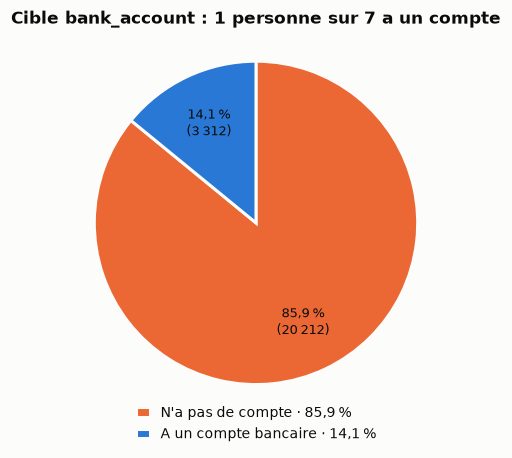

In [13]:
# Composition de la cible
fig, ax = plt.subplots(figsize=(4.8, 4.2))
viz.pie(
    ax,
    df[T].map(viz.LABELS_TARGET).value_counts().reindex(viz.LABELS_TARGET.values()),
    "Cible bank_account : 1 personne sur 7 a un compte",
    colors=[viz.NO, viz.YES],
)
viz.save(fig, "02_cible_camembert")
plt.show()

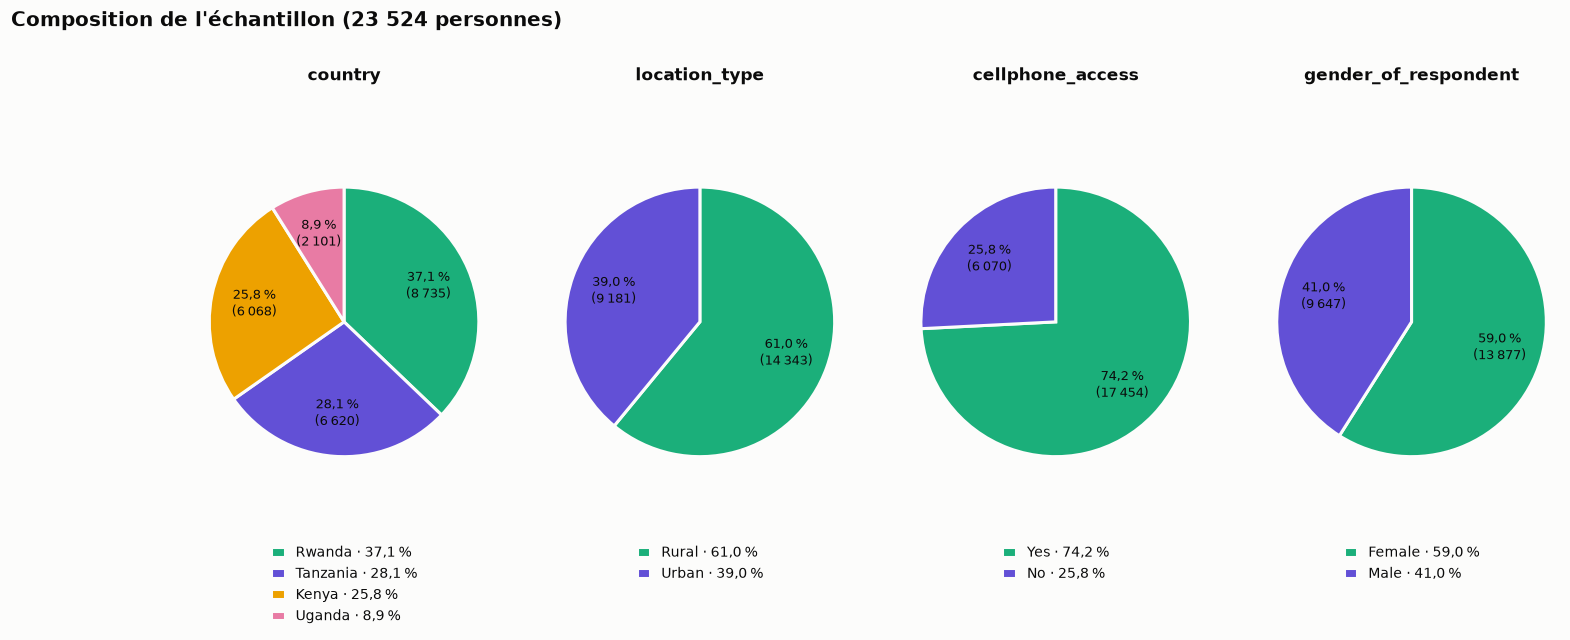

In [14]:
# Composition des variables à 2–4 modalités : camemberts
fig, axes = plt.subplots(1, 4, figsize=(16, 5.2))
for ax, col in zip(axes, ["country", "location_type", "cellphone_access", "gender_of_respondent"]):
    viz.pie(ax, df[col].value_counts(), col)
fig.suptitle("Composition de l'échantillon (23 524 personnes)", x=0.02, y=1.04, ha="left", fontweight="bold", fontsize=13)
viz.save(fig, "02_composition_camemberts")
plt.show()

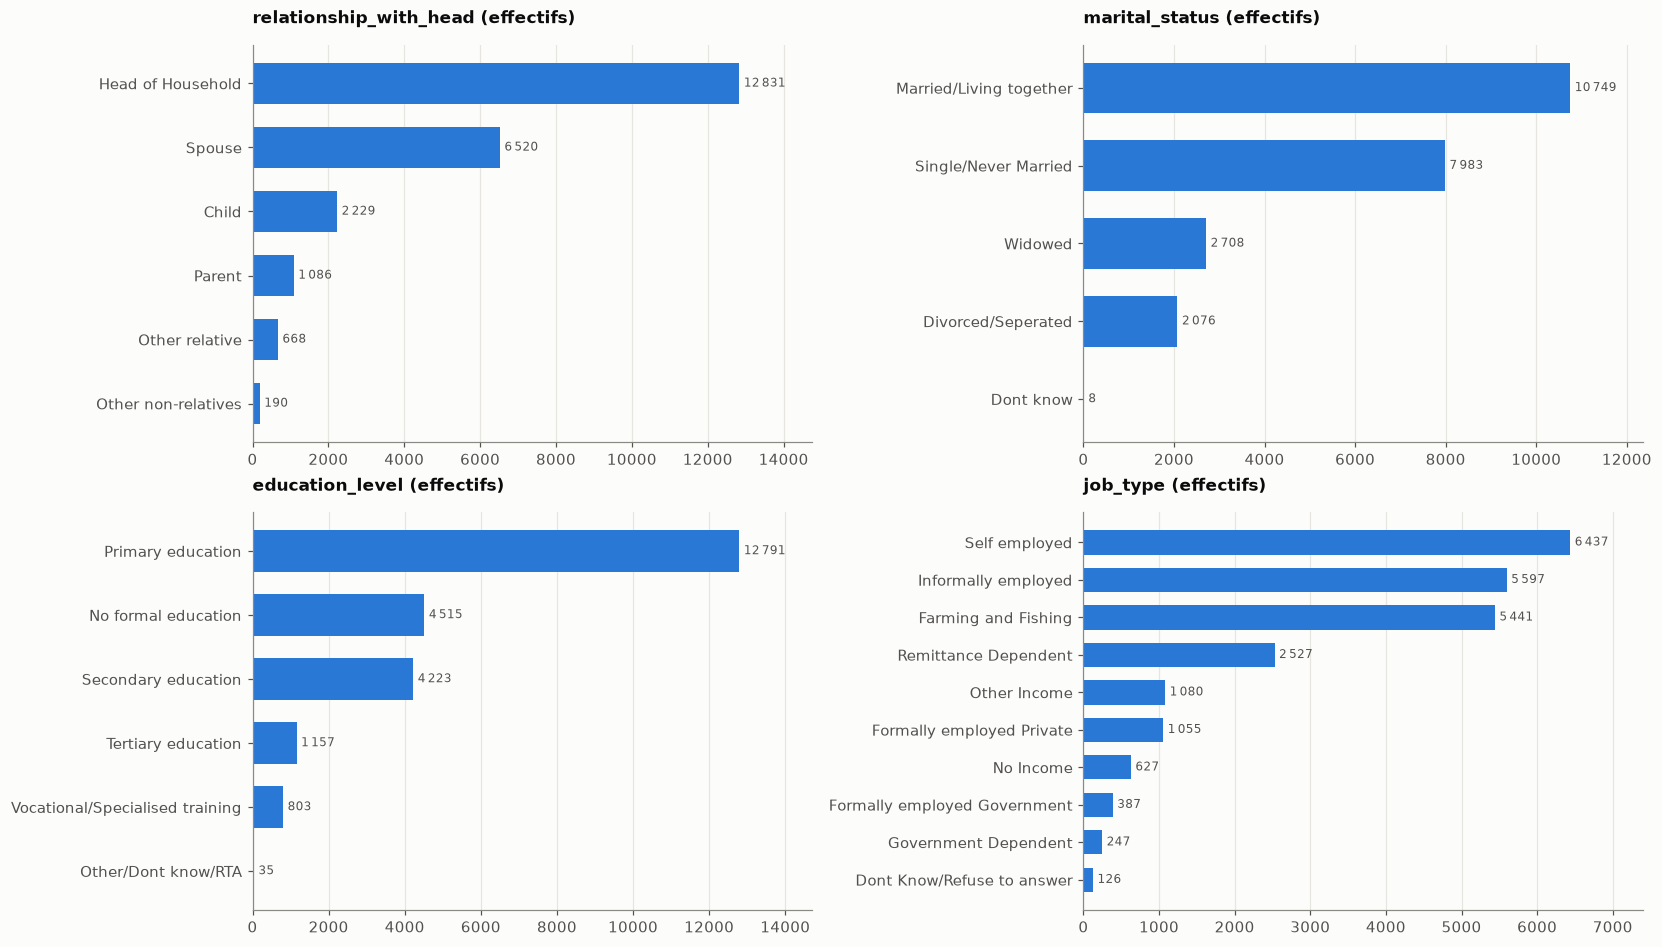

In [15]:
# Composition des variables à 5 modalités ou plus : barres triées
fig, axes = plt.subplots(2, 2, figsize=(15, 8.5), layout="constrained")
for ax, col in zip(axes.ravel(), ["relationship_with_head", "marital_status", "education_level", "job_type"]):
    viz.count_bars(ax, df[col].value_counts(), f"{col} (effectifs)")
viz.save(fig, "02_composition_barres")
plt.show()

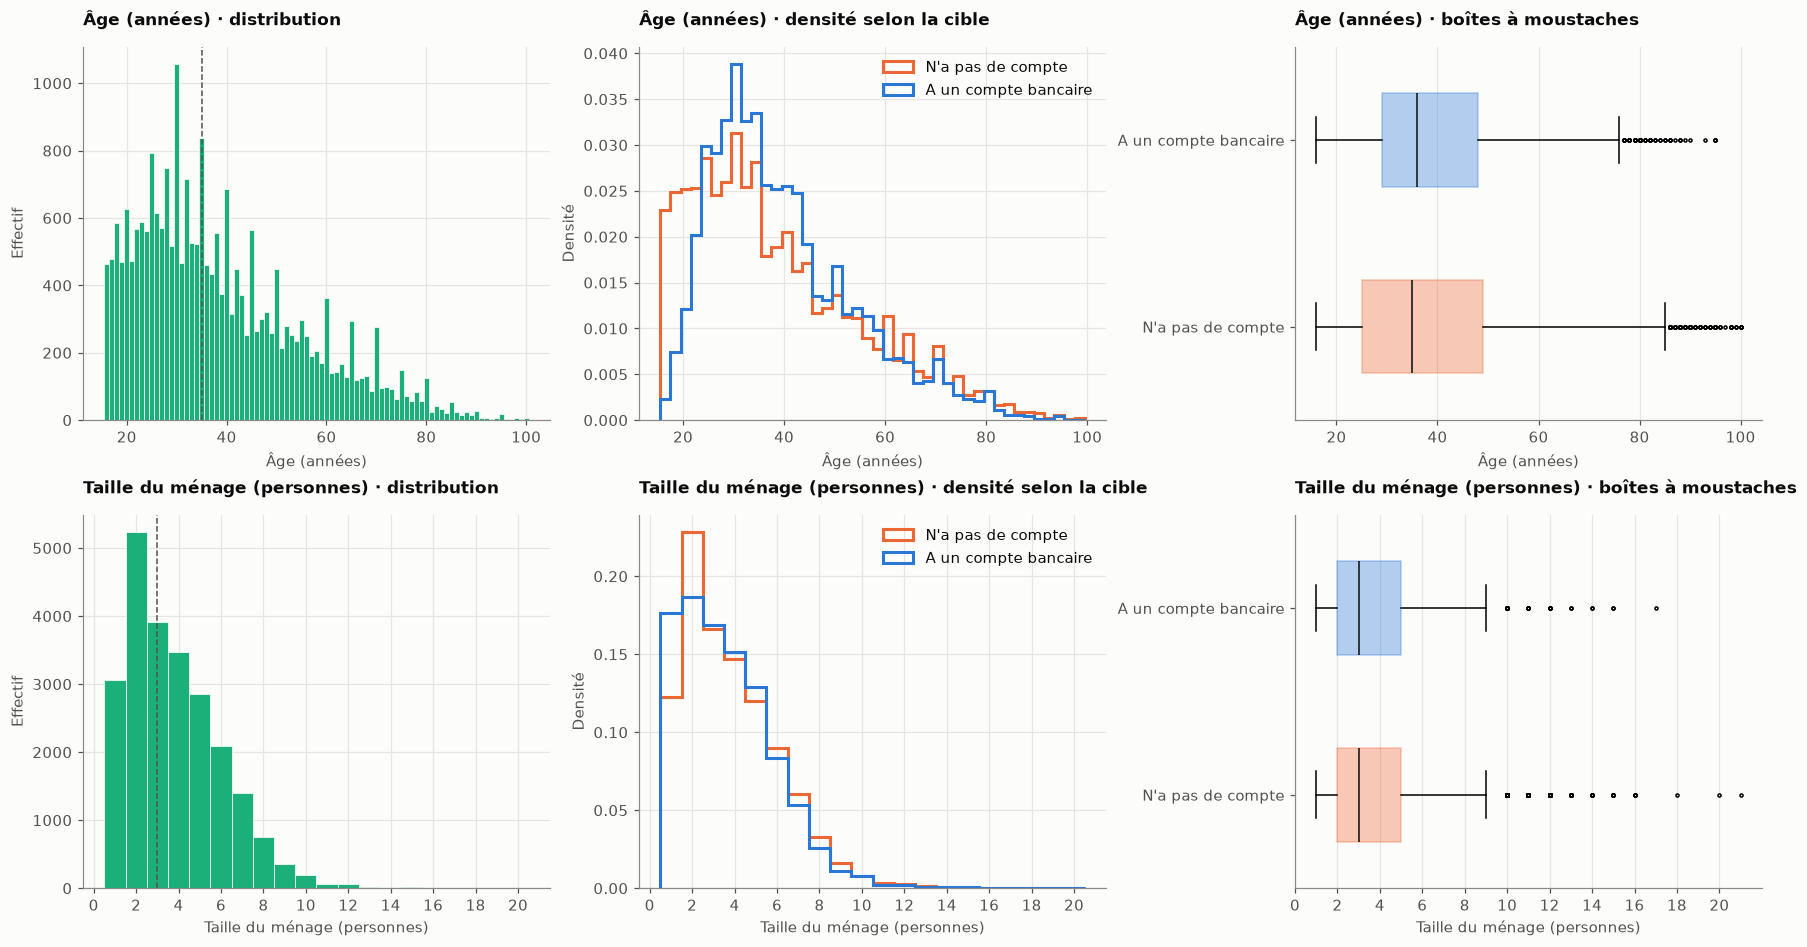

In [16]:
# Distributions des deux variables numériques, globalement puis selon la cible
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), layout="constrained")
# (bins fins pour la distribution, bins de 2 ans pour comparer les densités)
specs = {"age_of_respondent": (np.arange(15.5, 101.5, 1), np.arange(15.5, 101.5, 2), "Âge (années)"),
         "household_size": (np.arange(0.5, 21.5, 1), np.arange(0.5, 21.5, 1), "Taille du ménage (personnes)")}
for row, (col, (bins, bins_dens, label)) in zip(axes, specs.items()):
    row[0].hist(df[col], bins=bins, color=viz.SERIES[2], edgecolor=viz.SURFACE, linewidth=0.5)
    row[0].axvline(df[col].median(), color=viz.INK_2, ls="--", lw=1)
    row[0].set(title=f"{label} · distribution", xlabel=label, ylabel="Effectif")
    for v, color in [(0, viz.NO), (1, viz.YES)]:
        row[1].hist(df.loc[df[T] == v, col], bins=bins_dens, density=True, histtype="step",
                    lw=2, color=color, label=viz.LABELS_TARGET[v])
    row[1].set(title=f"{label} · densité selon la cible", xlabel=label, ylabel="Densité")
    row[1].legend()
    bp = row[2].boxplot([df.loc[df[T] == v, col] for v in (0, 1)], orientation="horizontal", widths=0.5,
                        patch_artist=True, tick_labels=list(viz.LABELS_TARGET.values()),
                        medianprops={"color": viz.INK}, flierprops={"markersize": 2})
    for patch, color in zip(bp["boxes"], (viz.NO, viz.YES)):
        patch.set(facecolor=color, alpha=0.35, edgecolor=color)
    row[2].set(title=f"{label} · boîtes à moustaches", xlabel=label)
    row[2].grid(axis="y", visible=False)
for ax in axes[1]:
    ax.set_xticks(range(0, 22, 2))
viz.save(fig, "02_distributions_numeriques")
plt.show()

In [17]:
# Arrondi des âges : part des âges multiples de 5 (≈ 20 % attendus sans arrondi)
heap = df["age_of_respondent"].mod(5).eq(0)
print(f"Âges multiples de 5 : {heap.mean():.1%} (attendu ≈ 20 %)")
print("30 ans :", (df["age_of_respondent"] == 30).sum(), "· 29 ans :", (df["age_of_respondent"] == 29).sum(),
      "· 31 ans :", (df["age_of_respondent"] == 31).sum())
heap.groupby(df["country"]).mean().round(3).to_frame("part des âges multiples de 5")

Âges multiples de 5 : 28.1% (attendu ≈ 20 %)
30 ans : 1056 · 29 ans : 517 · 31 ans : 467


,part des âges multiples de 5
country,
Kenya,0.301
Rwanda,0.251
Tanzania,0.293
Uganda,0.315


**Réponse Q2.1.**

- **Dimensions** : 23 524 lignes × 13 colonnes, **aucune valeur manquante**, aucune ligne strictement dupliquée (toutes ont un `uniqueid`).
- **Types** (tableau ci-dessus, fixés dans `eda.py`) :

| Type | Colonnes |
|---|---|
| Numériques (discrètes) | `household_size`, `age_of_respondent` |
| Binaires | `location_type`, `cellphone_access`, `gender_of_respondent` (et la cible `bank_account`) |
| Nominales | `country`, `relationship_with_head`, `marital_status`, `job_type` |
| Ordinale | `education_level` (aucune → primaire → secondaire → professionnel / supérieur) |
| Identifiant | `uniqueid` |
| Numérique en apparence, catégorielle en réalité | `year` (3 valeurs, redondante avec `country`, Q2.3) |

- **Composition** : le Rwanda fournit 37 % des lignes, l'Ouganda seulement 9 % ; 61 % des personnes vivent en milieu rural, 74 % ont accès à un téléphone, 59 % sont des femmes ; 54 % ont au plus l'école primaire.
- **Variables numériques** : l'âge va de 16 à 100 ans (médiane 35, asymétrie à droite 0,84) ; la taille du ménage de 1 à 21 (médiane 3, longue queue : 54 ménages de plus de 12 personnes). Ces valeurs extrêmes sont plausibles, on les garde.
- **Âges arrondis** : l'histogramme présente des pics à 30, 40, 50, 60 ans. **28,1 %** des âges sont des multiples de 5, contre ≈ 20 % attendus (1 056 personnes de 30 ans, contre 517 de 29 ans et 467 de 31 ans). Beaucoup de personnes déclarent un âge approximatif : l'âge au an près est imprécis, ce qui plaide pour des **tranches d'âge** plutôt qu'un effet fin de l'âge.
- **Selon la cible**, les distributions numériques se superposent presque (âge moyen 39,6 contre 38,7 ans ; ménage 3,6 contre 3,8) : prises seules, ces variables séparent mal les classes. La relation avec l'âge est **non linéaire** (voir les compléments).

### Q2.2 · Part des personnes qui ont un compte bancaire, globalement puis par pays

In [18]:
print(f"Globalement : {global_rate:.2%} des personnes ont un compte bancaire")
by_country = eda.target_rate(df, "country")
by_country["part_des_positifs"] = by_country["positifs"] / by_country["positifs"].sum()
by_country.sort_values("taux", ascending=False).round(4)

Globalement : 14.08% des personnes ont un compte bancaire


,effectif,positifs,taux,part_effectif,part_des_positifs
country,,,,,
Kenya,6068,1521,0.2507,0.2579,0.4592
Rwanda,8735,1003,0.1148,0.3713,0.3028
Tanzania,6620,607,0.0917,0.2814,0.1833
Uganda,2101,181,0.0861,0.0893,0.0546


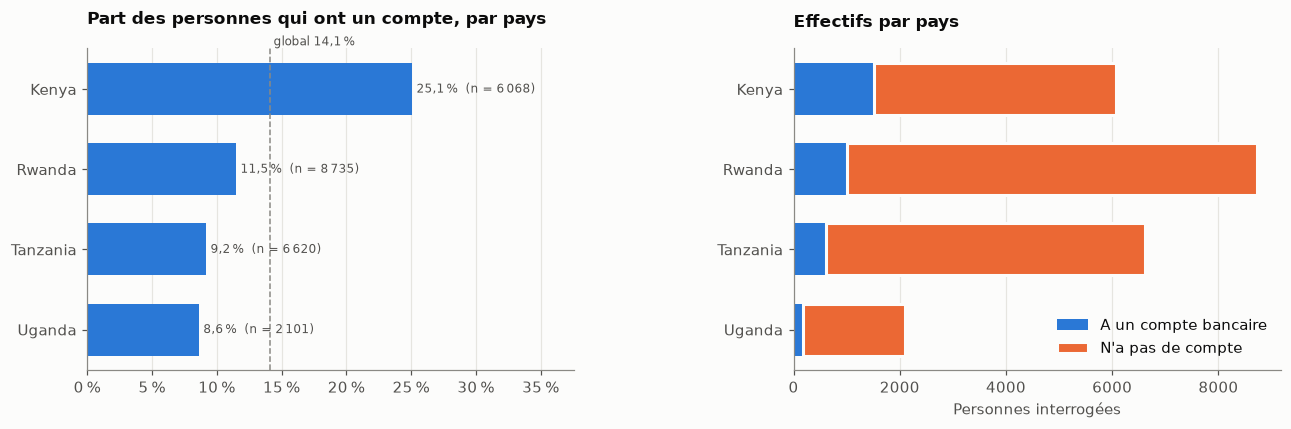

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"wspace": 0.45})
viz.rate_bars(ax1, by_country, "Part des personnes qui ont un compte, par pays", global_rate)
counts = pd.crosstab(df["country"], df[T]).loc[by_country.sort_values("taux").index]
ax2.barh(counts.index, counts[1], color=viz.YES, label=viz.LABELS_TARGET[1], height=0.65)
ax2.barh(counts.index, counts[0], left=counts[1], color=viz.NO, label=viz.LABELS_TARGET[0],
         height=0.65, edgecolor=viz.SURFACE, linewidth=2)
ax2.set(title="Effectifs par pays", xlabel="Personnes interrogées")
ax2.grid(axis="y", visible=False)
ax2.legend(loc="lower right")
viz.save(fig, "02_taux_par_pays")
plt.show()

**Réponse Q2.2.** Globalement **14,08 %** des personnes ont un compte bancaire. Ce qui frappe, c'est l'**hétérogénéité entre pays** : **25,1 % au Kenya**, contre 11,5 % au Rwanda, 9,2 % en Tanzanie et **8,6 % en Ouganda**, soit un facteur 3. Le Kenya représente 26 % des lignes mais **46 % des personnes qui ont un compte**.

**Conséquences**
- **Découpage** : la classe positive est rare et inégalement répartie ; il faut **stratifier** le découpage train/test et les plis sur la cible pour garder 14 % partout (étape 4), et vérifier que chaque pays est bien représenté dans les deux parties (l'Ouganda ne compte que 2 101 lignes et 181 positifs).
- **Le pays est un facteur de confusion** : il est lié à la cible *et* aux autres variables (milieu, emploi, téléphone, voir le V de Cramér). Les scores globaux mélangent quatre populations différentes.
- **Appliquer le modèle dans un autre pays** (le Sénégal, par exemple) : la prévalence y sera différente (**décalage de prior**), donc les probabilités seront mal calibrées, la somme des probabilités (banque centrale) biaisée et le seuil $t^*$ mal placé. Les modalités peuvent aussi être codées autrement (voir `job_type`, Q2.6). On mesurera ce transfert par une validation croisée **groupée par pays** (Q4.4) et il faudra **recalibrer** sur des données locales.

### Q2.3 · Croiser `country` et `year`

year,2016,2017,2018
country,,,
Kenya,0,0,6068
Rwanda,8735,0,0
Tanzania,0,6620,0
Uganda,0,0,2101


V de Cramér (country, year) = 1.00


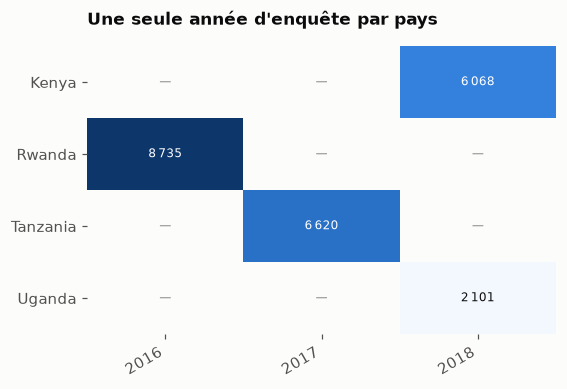

In [20]:
ct = pd.crosstab(df["country"], df["year"])
display(ct)
print(f"V de Cramér (country, year) = {eda.cramers_v(df['country'], df['year']):.2f}")

fig, ax = plt.subplots(figsize=(5.5, 3.4))
viz.heatmap(ax, ct.where(ct > 0), "Une seule année d'enquête par pays", fmt="{:,.0f}")
viz.save(fig, "02_pays_annee")
plt.show()

**Réponse Q2.3.** Chaque pays n'a été enquêté **qu'une seule année** : Rwanda 2016, Tanzanie 2017, Kenya et Ouganda 2018. `year` est donc **entièrement déterminée par `country`** (V de Cramér = 1) ; elle est même plus grossière, puisque le Kenya et l'Ouganda partagent 2018.

- `year` **n'apporte aucune information** que `country` n'apporte pas : impossible de séparer un effet « année » d'un effet « pays ».
- Elle serait même trompeuse : un modèle appliqué en 2019 ou plus tard rencontrerait une valeur jamais vue.

**Décision : on supprime `year`** (étape 3) et on garde `country`.

### Q2.4 · `uniqueid` est-il un identifiant ?

In [21]:
id_num = df["uniqueid"].str.extract(r"(\d+)", expand=False).astype(int)
pd.DataFrame(
    {
        "lignes": df.groupby("country").size(),
        "uniqueid distincts": df.groupby("country")["uniqueid"].nunique(),
        "unique dans le pays": df.groupby("country")["uniqueid"].apply(lambda s: s.is_unique),
        "numéro min": id_num.groupby(df["country"]).min(),
        "numéro max": id_num.groupby(df["country"]).max(),
        "ROC-AUC du numéro seul": [roc_auc_score(g[T], id_num[g.index]) for _, g in df.groupby("country")],
    }
).round(3)

,lignes,uniqueid distincts,unique dans le pays,numéro min,numéro max,ROC-AUC du numéro seul
country,,,,,,
Kenya,6068,6068,True,1,6071,0.490
Rwanda,8735,8735,True,1,8759,0.486
Tanzania,6620,6620,True,1,6637,0.498
Uganda,2101,2101,True,1,2117,0.435


In [22]:
print("uniqueid unique dans tout le fichier :", df["uniqueid"].is_unique,
      f"({df['uniqueid'].nunique():,} valeurs distinctes pour {len(df):,} lignes)")
print("(country, uniqueid) unique :", not df.duplicated(["country", "uniqueid"]).any())

uniqueid unique dans tout le fichier : False (8,735 valeurs distinctes pour 23,524 lignes)
(country, uniqueid) unique : True


**Réponse Q2.4.**
- **Pas unique dans tout le fichier** : 8 735 valeurs distinctes pour 23 524 lignes, car la numérotation **recommence dans chaque pays** (`uniqueid_1` existe quatre fois).
- **Unique dans chaque pays** : la vraie clé d'une personne est le couple **(`country`, `uniqueid`)**.
- **Ce n'est pas une variable explicative** : c'est une étiquette arbitraire, sans sens pour une nouvelle personne. Le numéro suit l'ordre de collecte et porte même un léger signal en Ouganda (ROC-AUC 0,435 au lieu de 0,5) : un artefact (ordre des régions enquêtées) qu'un modèle pourrait apprendre et qui n'existera pas en production. En one-hot, il permettrait aussi de mémoriser chaque ligne.

**Décision : on exclut `uniqueid` des variables explicatives** (étape 3).

### Q2.5 · Profils identiques et étiquettes contradictoires

In [23]:
dups = eda.duplicate_profiles(df)
display(pd.Series(dups, name="valeur").to_frame().assign(part_des_lignes=lambda t: t["valeur"] / len(df)))

# Le guide : df.groupby(colonnes)[cible].agg(["size", "nunique"])
profile_cols = [c for c in df.columns if c not in ("uniqueid", T)]
prof = df.groupby(profile_cols)[T].agg(["size", "nunique", "mean"])
prof[prof["size"] > 1].sort_values("size", ascending=False).head(5)

,valeur,part_des_lignes
profils_distincts,18611,0.7911
profils_repetes,2584,0.1098
lignes_dans_profils_repetes,7497,0.3187
profils_contradictoires,484,0.0206
lignes_dans_profils_contradictoires,1746,0.0742
erreurs_irreductibles,516,0.0219


size  \
country  year location_type cellphone_access household_size age_of_respondent gender_of_respondent relationship_with_head marital_status       education_level   job_type              
Tanzania 2017 Urban         Yes              2              36                Male                 Head of Household      Single/Never Married Primary education Self employed    24   
                                                            35                Male                 Head of Household      Single/Never Married Primary education Self employed    21   
                            No               2              30                Female               Spouse                 Single/Never Married Primary education Self employed    20   
                            Yes              2              30                Male                 Head of Household      Single/Never Married Primary education Self employed    19   
                            No               2              22                Female               Spouse                 Single/Never Married Primary education Self employed    19   

                                                                                                                                                                                nunique  \
country  year location_type cellphone_access household_size age_of_respondent gender_of_respondent relationship_with_head marital_status       education_level   job_type                 
Tanzania 2017 Urban         Yes              2              36                Male                 Head of Household      Single/Never Married Primary education Self employed        2   
                                                            35                Male                 Head of Household      Single/Never Married Primary education Self employed        2   
                            No               2              30                Female               Spouse                 Single/Never Married Primary education Self employed        1   
                            Yes              2              30                Male                 Head of Household      Single/Never Married Primary education Self employed        1   
                            No               2              22                Female               Spouse                 Single/Never Married Primary education Self employed        1   

                                                                                                                                                                                  mean  
country  year location_type cellphone_access household_size age_of_respondent gender_of_respondent relationship_with_head marital_status       education_level   job_type               
Tanzania 2017 Urban         Yes              2              36                Male                 Head of Household      Single/Never Married Primary education Self employed  0.1250  
                                                            35                Male                 Head of Household      Single/Never Married Primary education Self employed  0.0476  
                            No               2              30                Female               Spouse                 Single/Never Married Primary education Self employed  0.0000  
                            Yes              2              30                Male                 Head of Household      Single/Never Married Primary education Self employed  0.0000  
                            No               2              22                Female               Spouse                 Single/Never Married Primary education Self employed  0.0000

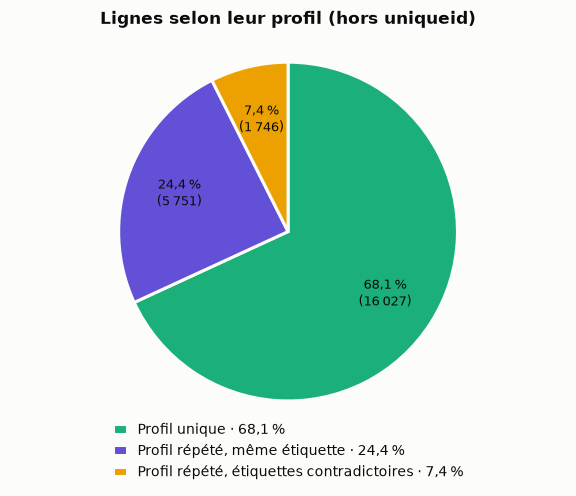

In [24]:
n_rep, n_contra = dups["lignes_dans_profils_repetes"], dups["lignes_dans_profils_contradictoires"]
parts = pd.Series(
    {
        "Profil unique": len(df) - n_rep,
        "Profil répété, même étiquette": n_rep - n_contra,
        "Profil répété, étiquettes contradictoires": n_contra,
    }
)
fig, ax = plt.subplots(figsize=(6.5, 4.4))
viz.pie(ax, parts, "Lignes selon leur profil (hors uniqueid)")
viz.save(fig, "02_profils_repetes")
plt.show()

**Réponse Q2.5.**
- **7 497 lignes (31,9 %)** partagent exactement leur profil avec au moins une autre ligne (2 584 profils répétés ; un profil apparaît jusqu'à 24 fois). Avec des variables aussi grossières (âge en années, quelques modalités), deux personnes différentes peuvent répondre exactement la même chose.
- **484 profils sont contradictoires** (au moins un *Yes* et un *No*) : **1 746 lignes (7,4 %)**. Pour ces lignes, **aucun modèle** ne peut avoir raison partout : même en prédisant la majorité de chaque profil, on commet au moins **516 erreurs (2,2 %)**. L'accuracy ne peut donc pas dépasser 97,8 %.
- **Lien avec $\sigma^2$ (slide 10)** : erreur $=$ biais$^2$ $+$ variance $+$ $\sigma^2$. Pour un même $x$, $y$ varie : c'est le **bruit irréductible**. Il vient de tout ce que le questionnaire ne mesure pas (revenu, distance à une agence, confiance dans les banques…). Aucun réglage d'hyperparamètre ne le fera baisser ; ces contradictions n'en sont qu'une **borne inférieure visible**.
- **Ce n'est pas une fuite** : ce sont des personnes différentes (clé `country`, `uniqueid` distincte), et aucune variable ne contient la cible. On ne supprime pas ces lignes : les profils répétés existeront aussi en production. Seule précaution : un modèle qui mémorise (arbre très profond) profitera un peu des copies présentes dans plusieurs plis ; on le verra dans l'écart entraînement/validation (étape 5).

### Q2.6 · Modalités rares (moins de 50 occurrences)

,variable,modalite,effectif
0,marital_status,Dont know,8
1,education_level,Other/Dont know/RTA,35


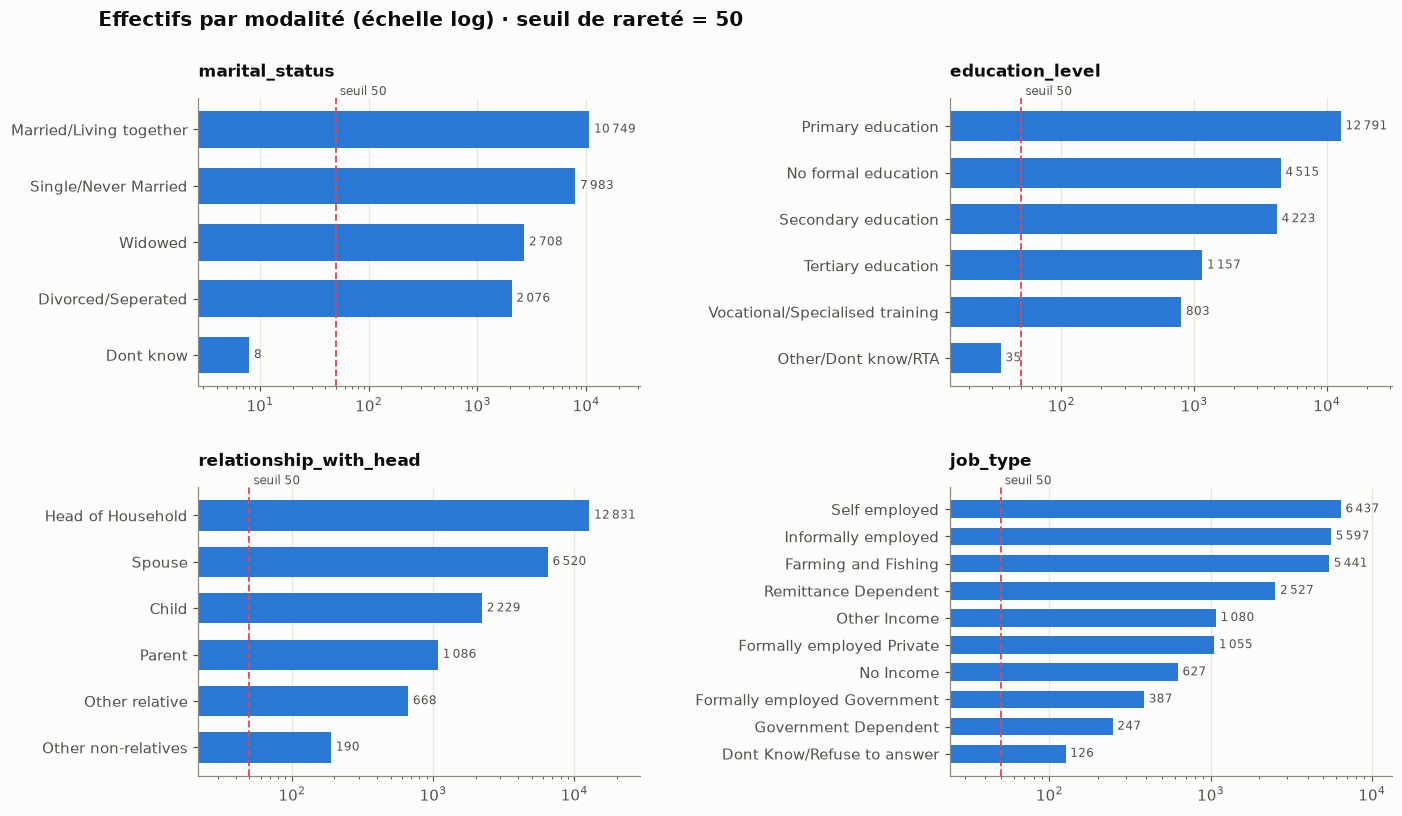

In [25]:
rare = eda.rare_categories(df, eda.CATEGORICAL, threshold=50)
display(rare)

fig, axes = plt.subplots(2, 2, figsize=(14, 8), gridspec_kw={"wspace": 0.7, "hspace": 0.35})
for ax, col in zip(axes.ravel(), ["marital_status", "education_level", "relationship_with_head", "job_type"]):
    viz.count_bars(ax, df[col].value_counts(), col, threshold=50)
    ax.set_xscale("log")
fig.suptitle("Effectifs par modalité (échelle log) · seuil de rareté = 50", x=0.06, ha="left",
             fontweight="bold", fontsize=13)
viz.save(fig, "02_modalites_rares")
plt.show()

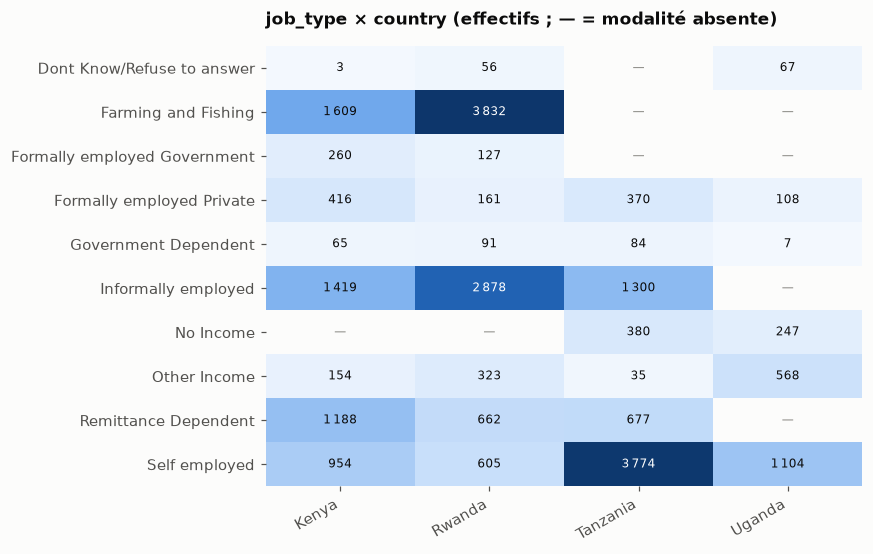

In [26]:
# Les modalités de job_type dépendent du pays : questionnaires différents
jobs = pd.crosstab(df["job_type"], df["country"])
fig, ax = plt.subplots(figsize=(7, 5.2))
viz.heatmap(ax, jobs.where(jobs > 0), "job_type × country (effectifs ; — = modalité absente)",
            fmt="{:,.0f}")
viz.save(fig, "02_job_type_par_pays")
plt.show()

**Réponse Q2.6.** Deux modalités ont moins de 50 occurrences :

| Variable | Modalité | Effectif |
|---|---|---|
| `marital_status` | *Dont know* | **8** |
| `education_level` | *Other/Dont know/RTA* | **35** |

Ce sont des quasi-valeurs manquantes (« ne sait pas », « refus de répondre »).

**Problèmes**
- **Encodage** : en one-hot, une colonne qui ne contient que 8 « 1 » donne un coefficient instable, estimé sur une poignée de personnes (variance élevée, surapprentissage).
- **Validation croisée** : sur 5 plis, chaque pli de validation n'en contient qu'un ou deux. Une modalité peut être **absente de l'entraînement mais présente en validation** : un `OneHotEncoder` par défaut lève alors une erreur, ou l'ignore silencieusement. Les scores de ces lignes sont du bruit.
- **Solution** (étape 3, Q3.2) : regrouper les modalités rares dans une modalité « infrequent » avec `OneHotEncoder(min_frequency=20, handle_unknown="infrequent_if_exist")`.

**Piège supplémentaire, plus grave : `job_type` n'est pas codé de la même façon selon le pays.** *Farming and Fishing* et *Formally employed Government* n'existent pas en Tanzanie ni en Ouganda ; *Informally employed* et *Remittance Dependent* n'existent pas en Ouganda ; *No Income* n'existe qu'en Tanzanie et en Ouganda. La variable encode donc en partie le **questionnaire**, donc le pays. En validation croisée groupée par pays (Q4.4), le pays laissé de côté apportera des modalités **jamais vues** à l'entraînement.

### Q2.7 · Part des personnes qui ont un compte selon l'éducation, l'emploi et le téléphone

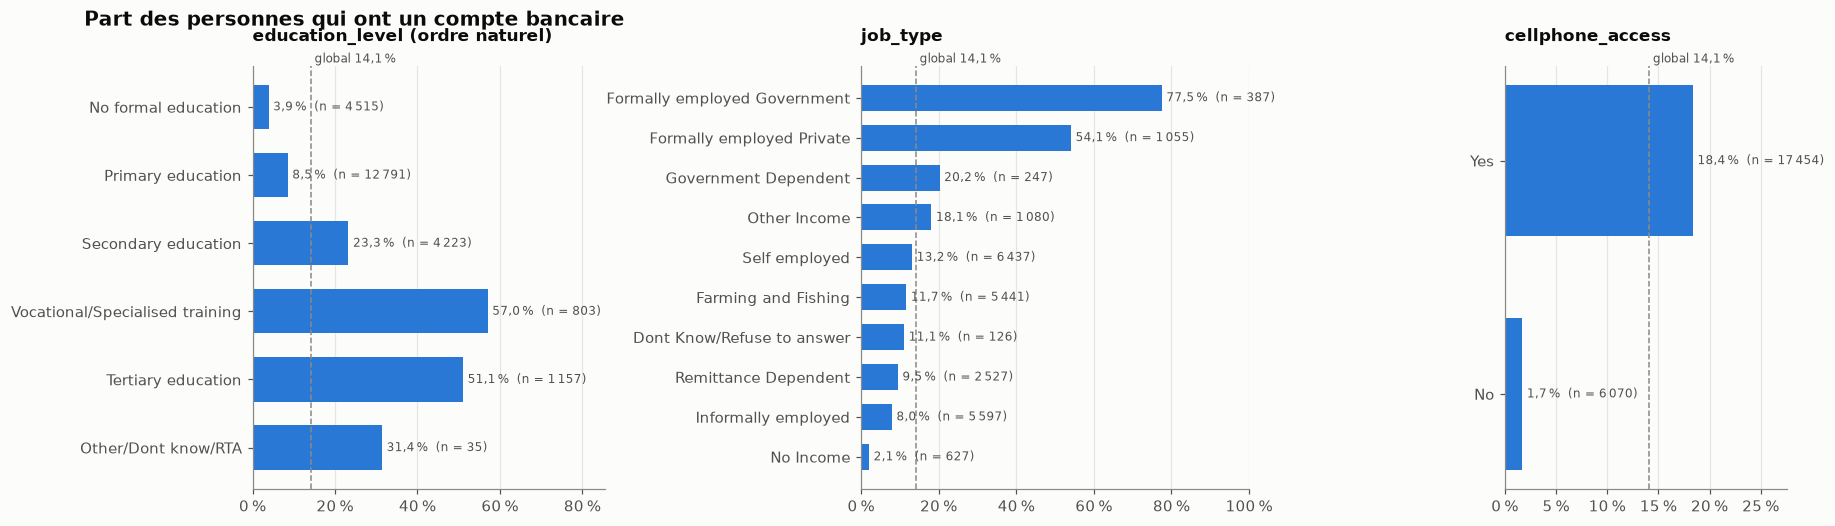

Parmi les personnes qui ont un compte, 96.9% ont accès à un téléphone.


In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"wspace": 0.75, "width_ratios": [1, 1.1, 0.8]})
edu = eda.target_rate(df, "education_level").reindex(eda.EDUCATION_ORDER)
viz.rate_bars(axes[0], edu, "education_level (ordre naturel)", global_rate, sort=False)
viz.rate_bars(axes[1], eda.target_rate(df, "job_type"), "job_type", global_rate)
viz.rate_bars(axes[2], eda.target_rate(df, "cellphone_access"), "cellphone_access", global_rate)
fig.suptitle("Part des personnes qui ont un compte bancaire", x=0.04, ha="left",
             fontweight="bold", fontsize=13)
viz.save(fig, "02_taux_education_emploi_telephone")
plt.show()
share = df.loc[df[T] == 1, "cellphone_access"].eq("Yes").mean()
print(f"Parmi les personnes qui ont un compte, {share:.1%} ont accès à un téléphone.")

**Réponse Q2.7.** Trois hypothèses, à confronter à l'interprétation du modèle (étape 11) :

1. **H1 · L'éducation est le premier facteur, et son effet est croissant.** La part passe de **3,9 %** sans éducation formelle à 8,5 % (primaire), 23,3 % (secondaire), puis **51,1 %** (supérieur) et **57,0 %** (formation professionnelle). C'est la variable la plus associée à la cible (V de Cramér 0,39). L'ordre est presque parfait : un encodage **ordinal** a du sens (Q3.3).
2. **H2 · Un revenu formel et régulier va de pair avec un compte.** 77,5 % des salariés de l'État et 54,1 % des salariés du privé en ont un, contre 8,0 % des travailleurs informels et **2,1 %** des personnes sans revenu (V = 0,36). Un salaire versé sur un compte en est sans doute la raison.
3. **H3 · Le téléphone est une quasi-condition nécessaire.** 18,4 % des personnes qui ont un téléphone ont un compte, contre **1,7 %** sans téléphone ; **96,9 %** des personnes qui ont un compte ont un téléphone. Sans téléphone, même un diplômé du supérieur n'a un compte que dans 6,6 % des cas (interactions ci-dessous).

On s'attend donc à retrouver `education_level`, `job_type` et `cellphone_access` (puis `country`) en tête des importances à l'étape 11. Ce sont des **associations**, pas des causes (Q11.5).

### Compléments · les autres variables

Les questions du guide ne couvrent pas toutes les variables. On regarde aussi le milieu, le genre, la place dans le ménage, le statut marital, l'âge et la taille du ménage.

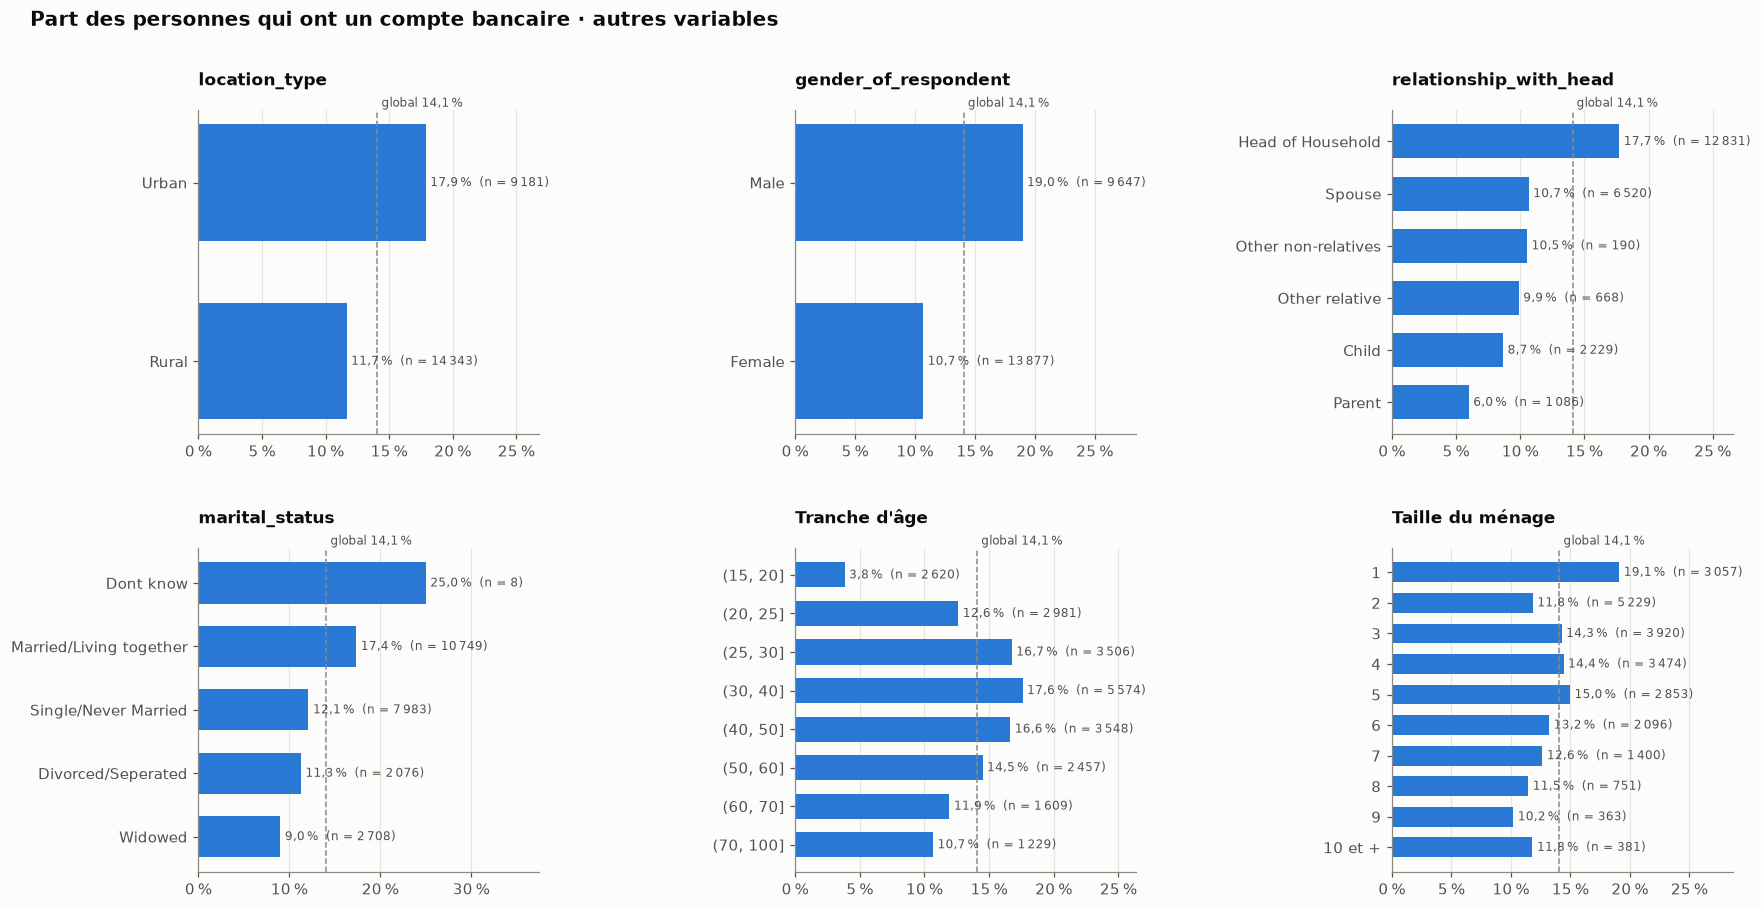

In [28]:
df_plot = df.assign(
    age_tranche=pd.cut(df["age_of_respondent"], [15, 20, 25, 30, 40, 50, 60, 70, 100]),
    taille_menage=df["household_size"].clip(upper=10).astype(str).replace("10", "10 et +"),
)
fig, axes = plt.subplots(2, 3, figsize=(18, 9), gridspec_kw={"wspace": 0.75, "hspace": 0.35})
for ax, col in zip(axes[0], ["location_type", "gender_of_respondent", "relationship_with_head"]):
    viz.rate_bars(ax, eda.target_rate(df, col), col, global_rate)
viz.rate_bars(axes[1, 0], eda.target_rate(df, "marital_status"), "marital_status", global_rate)
viz.rate_bars(axes[1, 1], eda.target_rate(df_plot, "age_tranche"), "Tranche d'âge", global_rate, sort=False)
hh = eda.target_rate(df_plot, "taille_menage").reindex([str(i) for i in range(1, 10)] + ["10 et +"])
viz.rate_bars(axes[1, 2], hh, "Taille du ménage", global_rate, sort=False)
fig.suptitle("Part des personnes qui ont un compte bancaire · autres variables", x=0.04,
             ha="left", fontweight="bold", fontsize=13)
viz.save(fig, "02_taux_autres_variables")
plt.show()

**Lecture.**
- **Milieu** : 17,9 % en ville contre 11,7 % à la campagne.
- **Genre** : 19,0 % des hommes contre 10,7 % des femmes (Q1.6).
- **Place dans le ménage** : les chefs de ménage (17,7 %) ont nettement plus souvent un compte que les parents du chef (6,0 %) ou ses enfants (8,7 %).
- **Statut marital** : les personnes mariées ont le plus souvent un compte (17,4 %).
- **Âge : relation en U inversé**, très non linéaire. 3,8 % chez les 16–20 ans, maximum vers **31–40 ans (17,6 %)**, puis baisse jusqu'à 10,7 % après 70 ans. Une régression logistique avec l'âge en terme linéaire ne peut pas représenter cette forme : il faudra des tranches, un terme au carré ou des arbres (piste pour Q3.5).
- **Taille du ménage** : effet faible, sauf les personnes seules (19,1 %).

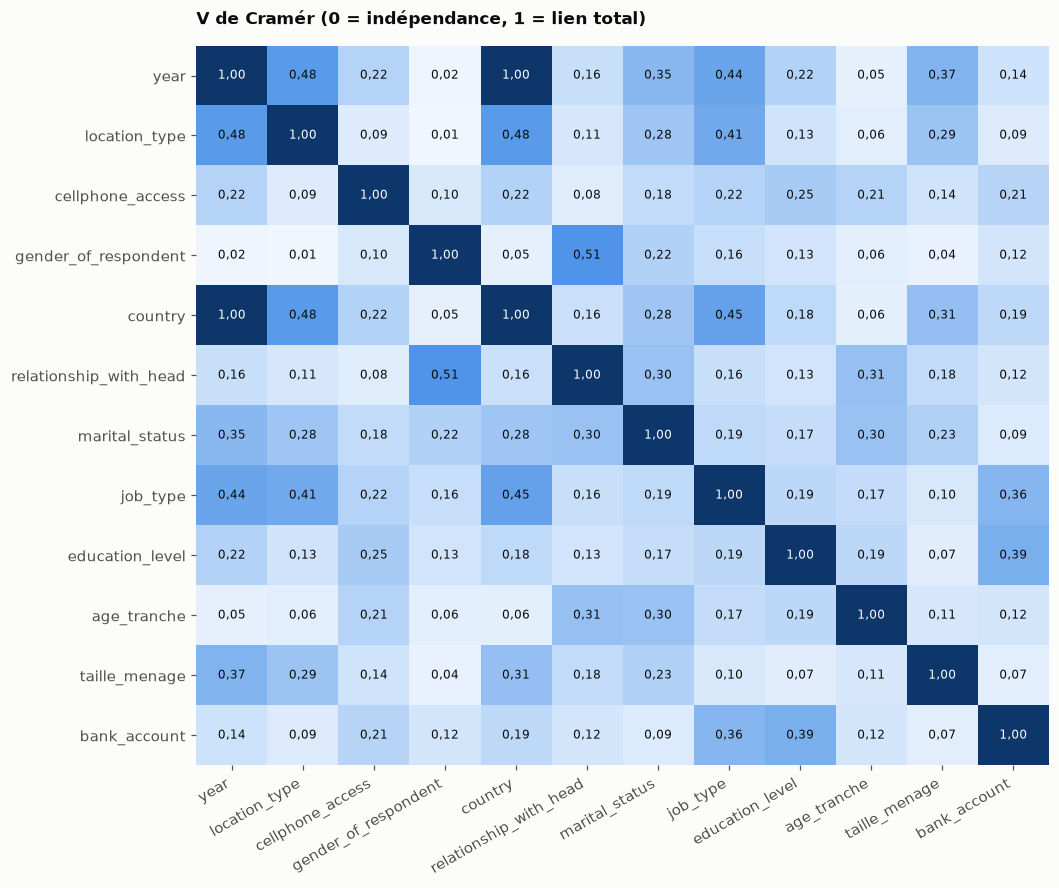

,V avec la cible
education_level,0.388
job_type,0.359
cellphone_access,0.210
country,0.189
year,0.144
age_tranche,0.122
relationship_with_head,0.118
gender_of_respondent,0.117
marital_status,0.091
location_type,0.087


In [29]:
# Associations entre toutes les variables catégorielles et la cible (V de Cramér)
assoc_cols = ["year", *eda.CATEGORICAL, T]
V = eda.cramers_v_matrix(df_plot.assign(age_tranche=df_plot["age_tranche"].astype(str)),
                         [*assoc_cols[:-1], "age_tranche", "taille_menage", T])
fig, ax = plt.subplots(figsize=(10, 8.5))
viz.heatmap(ax, V, "V de Cramér (0 = indépendance, 1 = lien total)", fmt="{:.2f}", vmin=0, vmax=1)
viz.save(fig, "02_cramers_v")
plt.show()
V[T].drop(T).sort_values(ascending=False).round(3).to_frame("V avec la cible")

**Lecture du V de Cramér.**
- **Avec la cible** : `education_level` (0,39) et `job_type` (0,36) dominent, puis `cellphone_access` (0,21), `country` (0,19), l'âge en tranches, `year` (0,14, simple reflet du pays), le genre et la place dans le ménage (0,12). Aucune variable n'est déterminante seule.
- **Entre variables explicatives** : `year`–`country` = 1 (Q2.3) ; `location_type`–`country` 0,48 et `job_type`–`country` 0,45 (le pays structure les autres variables, Q2.6) ; et **`gender_of_respondent`–`relationship_with_head` = 0,51** : la place dans le ménage est un **proxy du genre** (ci-dessous).

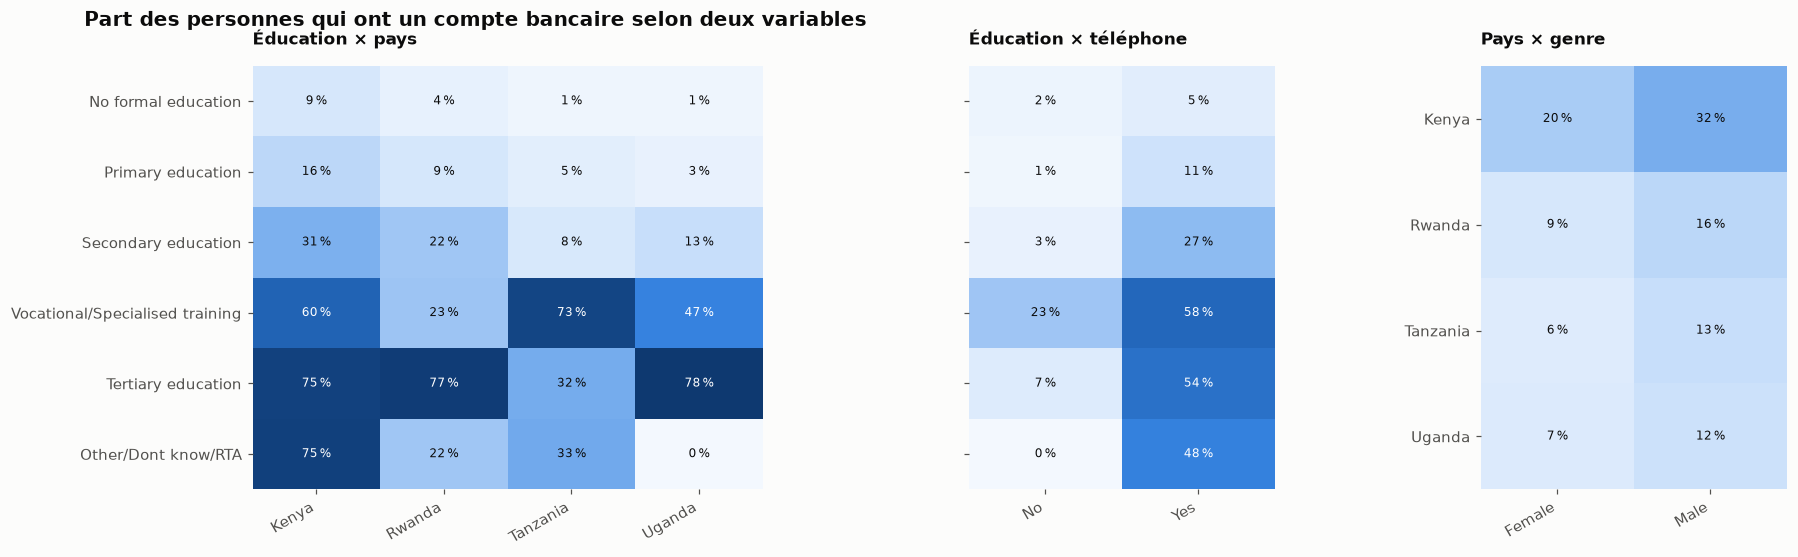

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"wspace": 0.55, "width_ratios": [1.25, 0.75, 0.75]})
rate = lambda r, c: pd.crosstab(df[r], df[c], values=df[T], aggfunc="mean")
viz.heatmap(axes[0], rate("education_level", "country").reindex(eda.EDUCATION_ORDER),
            "Éducation × pays", vmin=0, vmax=0.8)
viz.heatmap(axes[1], rate("education_level", "cellphone_access").reindex(eda.EDUCATION_ORDER),
            "Éducation × téléphone", vmin=0, vmax=0.8)
axes[1].set_yticklabels([])
viz.heatmap(axes[2], rate("country", "gender_of_respondent"), "Pays × genre", vmin=0, vmax=0.8)
fig.suptitle("Part des personnes qui ont un compte bancaire selon deux variables", x=0.04,
             ha="left", fontweight="bold", fontsize=13)
viz.save(fig, "02_interactions")
plt.show()

In [31]:
# Proxy du genre : répartition femmes/hommes selon la place dans le ménage
display(pd.crosstab(df["relationship_with_head"], df["gender_of_respondent"], normalize="index").round(3))
# Qualité des données : des « conjoints » déclarés célibataires
odd = df[(df["relationship_with_head"] == "Spouse") & (df["marital_status"] == "Single/Never Married")]
print(f"Spouse + Single/Never Married : {len(odd):,} lignes, dont {odd['country'].eq('Tanzania').sum():,} en Tanzanie")

gender_of_respondent,Female,Male
relationship_with_head,,
Child,0.525,0.475
Head of Household,0.404,0.596
Other non-relatives,0.584,0.416
Other relative,0.555,0.445
Parent,0.565,0.435
Spouse,0.986,0.014


Spouse + Single/Never Married : 1,847 lignes, dont 1,799 en Tanzanie


**Lecture des interactions et de la qualité des données.**
- **Éducation × pays** : l'effet de l'éducation existe dans les quatre pays, mais à des niveaux différents (primaire : 15,5 % au Kenya contre 3,4 % en Ouganda). Le pays décale le niveau ; l'éducation garde son ordre.
- **Éducation × téléphone** : sans téléphone, la part reste sous 7 % quel que soit le niveau d'éducation (sauf la formation professionnelle, petit effectif) ; avec téléphone, elle monte jusqu'à 58 %. Les deux effets se **combinent** : interaction que les arbres captent naturellement, pas une régression logistique sans terme croisé (H3).
- **Pays × genre** : l'écart femmes/hommes existe **dans chaque pays** (Kenya 20,1 % contre 31,7 %). Il ne s'explique pas par la composition par pays.
- **Proxy du genre** : **98,6 % des *Spouse* sont des femmes**. Retirer `gender_of_respondent` ne retirerait pas l'information (Q1.6, Q11.4).
- **Qualité des données** : 1 847 personnes sont déclarées *Spouse* mais *Single/Never Married*, dont **1 799 en Tanzanie**. C'est une incohérence de codage propre à l'enquête tanzanienne. On la garde (on ne peut pas savoir quelle réponse est juste) mais on la signale : le modèle apprendra des relations un peu différentes pour la Tanzanie.

### Synthèse · les décisions pour la suite

| Constat | Décision | Étape |
|---|---|---|
| 14 % de positifs, prévalence de 8,6 % à 25,1 % selon le pays | Découpage et plis **stratifiés** sur la cible ; PR-AUC comme métrique principale | 4 |
| `year` entièrement déterminée par `country` | **Supprimer `year`** | 3 |
| `uniqueid` : identifiant, numérotation par pays, signal artificiel | **Exclure `uniqueid`** | 3 |
| 2 modalités < 50 occurrences (quasi-manquantes) | Regrouper : `min_frequency=20`, `handle_unknown="infrequent_if_exist"` | 3 |
| `job_type` codé différemment selon le pays | Attention aux modalités inconnues en CV groupée par pays | 4 |
| `education_level` ordonnée, effet croissant | One-hot **et** rang ordinal | 3 |
| Âge : relation en U inversé | Variable non linéaire (tranches ou terme au carré) ou arbres | 3, 5 |
| Interaction téléphone × éducation | Avantage attendu des arbres sur la régression logistique | 5, 6 |
| 7,4 % des lignes dans des profils contradictoires, ≥ 2,2 % d'erreurs inévitables | Bruit irréductible : ne pas espérer un score parfait | 5 |
| Pays très différents | CV groupée par pays pour mesurer le transfert ; recalibrer avant de déployer ailleurs | 4, 8 |
| Genre prédictif, *Spouse* = proxy du genre | Audit d'équité (recall femmes/hommes) | 11 |
| H1 éducation, H2 emploi formel, H3 téléphone | À confronter aux importances | 11 |

### Point de contrôle

In [32]:
assert df.shape == (23_524, 13)
assert df.isna().sum().sum() == 0
assert df[T].sum() == 3_312
print(f"✓ {df.shape[0]:,} lignes × {df.shape[1]} colonnes, aucune valeur manquante, "
      f"{df[T].sum():,} personnes qui ont un compte bancaire ({df[T].mean():.2%})")

✓ 23,524 lignes × 13 colonnes, aucune valeur manquante, 3,312 personnes qui ont un compte bancaire (14.08%)
